# Inleiding tot Deep Learning voor Computer Vision

Computer vision is een van de eerste en grootste successen van deep learning. We gebruiken dagelijks deep vision modellen, bijvoorbeeld in Google Photos, zoekmachines voor afbeeldingen en autonome voertuigen. Deep learning, en in het bijzonder convolutionele neurale netwerken (CNN's), begon tussen 2011 en 2015 opmerkelijke resultaten te boeken in beeldclassificatie. Vroege successen waren onder andere overwinningen in competities voor Chinese karakterherkenning, Duitse verkeersbordherkenning en de prestigieuze ImageNet Large-Scale Visual Recognition Challenge in 2012. Hoewel er aanvankelijk scepsis was, werd deep learning rond 2016 dominant in het computer vision onderzoek.

### Convolutionele Neurale Netwerken (CNN's)

Dit hoofdstuk introduceert convolutionele neurale netwerken (convnets), die nu bijna universeel worden gebruikt in computer vision toepassingen. CNN's zijn met name effectief voor beeldclassificatieproblemen, zelfs met kleine trainingsdatasets.

Een basis CNN bestaat uit een stapel van Conv2D (convolutionele) en MaxPooling2D (max pooling) lagen. In tegenstelling tot dense layers die globale patronen in de input leren, leren convolutionele lagen lokale patronen in kleine 2D-vensters van de inputafbeelding. Deze lokale patronen kunnen bijvoorbeeld randen of texturen zijn. &#x20;

### De Convolutionele Operatie

De convolutionele operatie is fundamenteel anders dan die in dense layers. Dense layers leren globale patronen, terwijl convolutionele lagen lokale patronen leren in de input. Dit geeft CNN's twee belangrijke eigenschappen:

- **Translatie-invariantie**: Een patroon dat op één plek in de afbeelding is geleerd, kan ook op een andere plek worden herkend. Een dense layer zou hetzelfde patroon opnieuw moeten leren als het op een nieuwe locatie verschijnt.
- **Ruimtelijke hiërarchieën van patronen**: De eerste convolutionele lagen leren kleine, lokale patronen (zoals randen), de volgende lagen leren grotere patronen die zijn samengesteld uit de kenmerken van de eerste lagen, enzovoort. Dit stelt CNN's in staat om steeds complexere visuele concepten efficiënt te leren.

Convoluties werken op feature maps, dit zijn rank-3 tensors met twee ruimtelijke assen (hoogte en breedte) en een diepte-as (ook wel het kanalen-as genoemd). De inputafbeelding zelf kan hierbij worden beschouwd als de eerste feature map. Elke volgende feature map is het resultaat van een convolutie op de vorige feature map(s). 

Deze transformatie maakt de inputafbeelding steeds abstracter. In de eerste lagen detecteert het netwerk eenvoudige kenmerken zoals randen en texturen. Naarmate de feature maps door meerdere convolutionele lagen gaan, combineren deze eenvoudige patronen zich tot complexere vormen, zoals contouren of objectonderdelen. In de hoogste lagen herkent het netwerk steeds abstractere en semantisch rijkere concepten, zoals een cijfer, een gezicht of een objectcategorie. Zo ontstaat een hiërarchische representatie van de visuele informatie die essentieel is voor taken zoals classificatie.

Voor een RGB-afbeelding is de diepte van de feature map 3 (rood, groen, blauw), voor een zwart-wit afbeelding is de diepte 1 (grijstinten). De convolutieoperatie extraheert patches (kleine vensters) uit de input feature map en past **dezelfde transformatie (een geleerde gewichtsmatrix, de convolutionele kernel)** toe op al deze patches, waardoor een output feature map ontstaat. De diepte van de output feature map is een parameter van de laag en staat voor verschillende filters die specifieke aspecten van de input coderen. Elke dimensie in de diepte-as van de feature map is een filter, en de 2D-tensor output[:, :, n] is de ruimtelijke kaart van de respons van dit filter over de input.

Convoluties worden gedefinieerd door twee belangrijke parameters: de grootte van de geëxtraheerde patches (meestal 3x3 of 5x5) en de diepte van de output feature map (het aantal berekende filters).

Opgepast: een convolutional kernel wordt initieel random geïnitialiseerd.  Dit betekent dat geen enkele kernel vooraf als doel heeft om bijvoorbeeld randen te detecteren...  **Die specialisatie gebeurt automatisch tijdens training**. Door training leert het netwerk dat sommige kernels er goed in zijn om de eindoutput (bijv. juiste classificatie) te verbeteren.

*Individuele kernels leren dus specifieke patronen in een afbeelding te herkennen, en het geheel van kernels in het netwerk zorgt ervoor dat het model zich specialiseert in het herkennen van een bepaald type objecten of categorieën (bv. katten, auto’s, landschappen).*

Dit is ook de reden waarom transfer learning werkt: de eerste lagen leren features extraheren die ook in andere afbeeldingen nuttig kunnen zijn.

### Border Effects en Padding

De outputbreedte en -hoogte van een convolutionele laag kunnen verschillen van de input door border effects. Bij een 5x5 input en een 3x3 filter zijn er bijvoorbeeld maar 9 posities waar het filter gecentreerd kan worden, wat resulteert in een 3x3 output. Om een output feature map met dezelfde ruimtelijke dimensies als de input te krijgen, kan padding worden gebruikt. Padding voegt rijen en kolommen toe aan de randen van de input feature map. In Keras kan padding worden ingesteld op "valid" (geen padding) of "same" (padding wordt toegepast om de outputafmetingen gelijk te houden aan de inputafmetingen).

### Convolutionele Strides

De stride van een convolutie is de afstand tussen de middelpunten van twee opeenvolgende filtervensters. Een stride groter dan 1 zorgt voor downsampling van de feature map.

### De Max-Pooling Operatie

Max pooling is een downsampling operatie die de grootte van de feature maps verkleint. Het werkt door vensters uit de input feature map te extraheren en de maximale waarde van elk kanaal in dat venster uit te voeren. Net als convolutie, werkt max pooling op lokale patches, maar in plaats van een geleerde transformatie wordt een hardgecodeerde 'max' operatie toegepast. Max pooling wordt meestal gedaan met 2x2 vensters en een stride van 2, waardoor de feature map met een factor 2 wordt verkleind.

Max pooling vermindert de grootte van de feature map, zodat het model minder data hoeft te verwerken.

Tegelijk zorgt max pooling ervoor dat latere lagen grotere delen van de originele afbeelding kunnen bekijken. Zo bouwt het netwerk een soort hiërarchie op:

- eerst kijkt het naar kleine details (zoals randen),
- dan naar grotere vormen (zoals een oog),
- en uiteindelijk naar hele objecten (zoals een gezicht of dier).

Hoewel ook strides in convolutionele lagen of average pooling (het gemiddelde van de waarden in het venster nemen) gebruikt kunnen worden voor downsampling, werkt max pooling over het algemeen beter omdat het de maximale aanwezigheid van kenmerken behoudt, wat informatiever is dan het gemiddelde of het overslaan van locaties met strides.

### Voorbeeld van een Simpel Convolutie Netwerk (Convnet)

Het document laat een eenvoudig CNN zien voor het classificeren van MNIST-cijfers, bestaande uit een stapel van Conv2D en MaxPooling2D lagen, gevolgd door een Flatten laag en een Dense classificatielaag met een softmax activatie voor 10-weg classificatie. De Flatten laag transformeert de 3D output van de laatste convolutionele laag naar een 1D vector die door de dense layers kan worden verwerkt. Dit eenvoudige CNN behaalt een hogere nauwkeurigheid op de MNIST-dataset dan een dense layer-netwerk.

In [1]:
from tensorflow import keras
from tensorflow.keras import layers

In [2]:
# maken van het model

# inputs
inputs = keras.Input(shape=(28,28,1))

# layers
x = layers.Conv2D(filters=32, kernel_size=3, activation='relu')(inputs)
# 3×3×1=9 parameters + 1 bias term = 10 maal 32 filters = 320 parameters.
x = layers.MaxPooling2D(pool_size=2)(x)
# MaxPooling: downsampling op de feature map dus geen parameters

x = layers.Conv2D(filters=64, kernel_size=3, activation='relu')(x)
x = layers.MaxPooling2D(pool_size=2)(x)

x = layers.Conv2D(filters=128, kernel_size=3, activation='relu')(x)

x = layers.Flatten()(x)
# reshapen van data voor de dense layer 

outputs = layers.Dense(10, activation='softmax')(x)

model = keras.Model(inputs=inputs, outputs=outputs)

model.summary()

Model: "model"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 input_1 (InputLayer)        [(None, 28, 28, 1)]       0         
                                                                 
 conv2d (Conv2D)             (None, 26, 26, 32)        320       
                                                                 
 max_pooling2d (MaxPooling2D  (None, 13, 13, 32)       0         
 )                                                               
                                                                 
 conv2d_1 (Conv2D)           (None, 11, 11, 64)        18496     
                                                                 
 max_pooling2d_1 (MaxPooling  (None, 5, 5, 64)         0         
 2D)                                                             
                                                                 
 conv2d_2 (Conv2D)           (None, 3, 3, 128)         73856 

In [3]:
from tensorflow.keras.datasets import mnist

In [4]:
(train_images, train_labels), (test_images, test_labels) = mnist.load_data()

In [5]:
train_images = train_images.reshape((60000, 28, 28, 1))
train_images = train_images.astype('float32')/255
test_images = test_images.reshape((10000, 28, 28, 1))
test_images = test_images.astype('float32')/255

In [6]:
model.compile(optimizer='rmsprop',
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])

In [7]:
model.fit(train_images, train_labels, epochs=5, batch_size=32)

Epoch 1/5
1875/1875 [==============================] - 10s 4ms/step - loss: 0.1295 - accuracy: 0.9604
Epoch 2/5
1875/1875 [==============================] - 6s 3ms/step - loss: 0.0408 - accuracy: 0.9874
Epoch 3/5
1875/1875 [==============================] - 6s 3ms/step - loss: 0.0290 - accuracy: 0.9912
Epoch 4/5
1875/1875 [==============================] - 6s 3ms/step - loss: 0.0228 - accuracy: 0.9932
Epoch 5/5
1875/1875 [==============================] - 5s 3ms/step - loss: 0.0180 - accuracy: 0.9947


### Face recognition

We trainen een eigen CNN dat als taak heeft een zo accuraat mogelijke gezichtsherkenning uit te voeren op een gezichtsdataset van celebrities.

Er zijn twee gezichtsdatasets beschikbaar:

'./Face_Recognition/15_Classes' bevat gezichten van 15 verschillende celebrities.

Werk in eerste instantie met de 15_classes dataset. 

In [8]:
!pip install -q scikit-image

You should consider upgrading via the '/usr/bin/python3 -m pip install --upgrade pip' command.


In [53]:
import os
from skimage.io import imread, imsave, imshow
from skimage import data, color, io, filters, morphology,transform, exposure, feature, util
import matplotlib.pyplot as plt

# Inlezen en preprocessen van de afbeeldingen
# nr_of_images = 5000
image_size = 100

faces = []
labels = []
# read train_images
path = './notebooks/Face_Recognition/15_Classes'
valid_images = [".jpg",".gif",".png"]

for f in os.listdir(path)[:]:
    ext = os.path.splitext(f)[1]
    if ext.lower() not in valid_images:
        continue
    im = imread(os.path.join(path,f)) 
    im = transform.resize(im,(image_size,image_size),mode='constant',anti_aliasing=True)
    faces.append(im)
    #s = re.sub('[0-9]\w+', '', f)
    s = os.path.splitext(f)[0]
    s = ''.join([i for i in s if not i.isdigit()])
    s = s.replace("_", "")
    labels.append(s)

In [54]:
faces

[array([[[0., 0., 0.],
         [0., 0., 0.],
         [0., 0., 0.],
         ...,
         [0., 0., 0.],
         [0., 0., 0.],
         [0., 0., 0.]],
 
        [[0., 0., 0.],
         [0., 0., 0.],
         [0., 0., 0.],
         ...,
         [0., 0., 0.],
         [0., 0., 0.],
         [0., 0., 0.]],
 
        [[0., 0., 0.],
         [0., 0., 0.],
         [0., 0., 0.],
         ...,
         [0., 0., 0.],
         [0., 0., 0.],
         [0., 0., 0.]],
 
        ...,
 
        [[0., 0., 0.],
         [0., 0., 0.],
         [0., 0., 0.],
         ...,
         [0., 0., 0.],
         [0., 0., 0.],
         [0., 0., 0.]],
 
        [[0., 0., 0.],
         [0., 0., 0.],
         [0., 0., 0.],
         ...,
         [0., 0., 0.],
         [0., 0., 0.],
         [0., 0., 0.]],
 
        [[0., 0., 0.],
         [0., 0., 0.],
         [0., 0., 0.],
         ...,
         [0., 0., 0.],
         [0., 0., 0.],
         [0., 0., 0.]]]),
 array([[[0., 0., 0.],
         [0., 0., 0.],
         

In [34]:
import numpy as np

[['Aaron Paul' 'Alvaro Morte' 'Amanda Crew' 'Amaury Nolasco' 'Anna Gunn'
  'Benedict Cumberbatch' 'Betsy Brandt' 'Brenton Thwaites'
  'alexandra daddario' 'alycia debnam carey face' 'amber heard face'
  'anne hathaway' 'barbara palvin face' 'bellamy blake face' 'bill gates']
 ['86' '91' '118' '113' '66' '81' '68' '130' '165' '144' '151' '151'
  '142' '89' '86']]


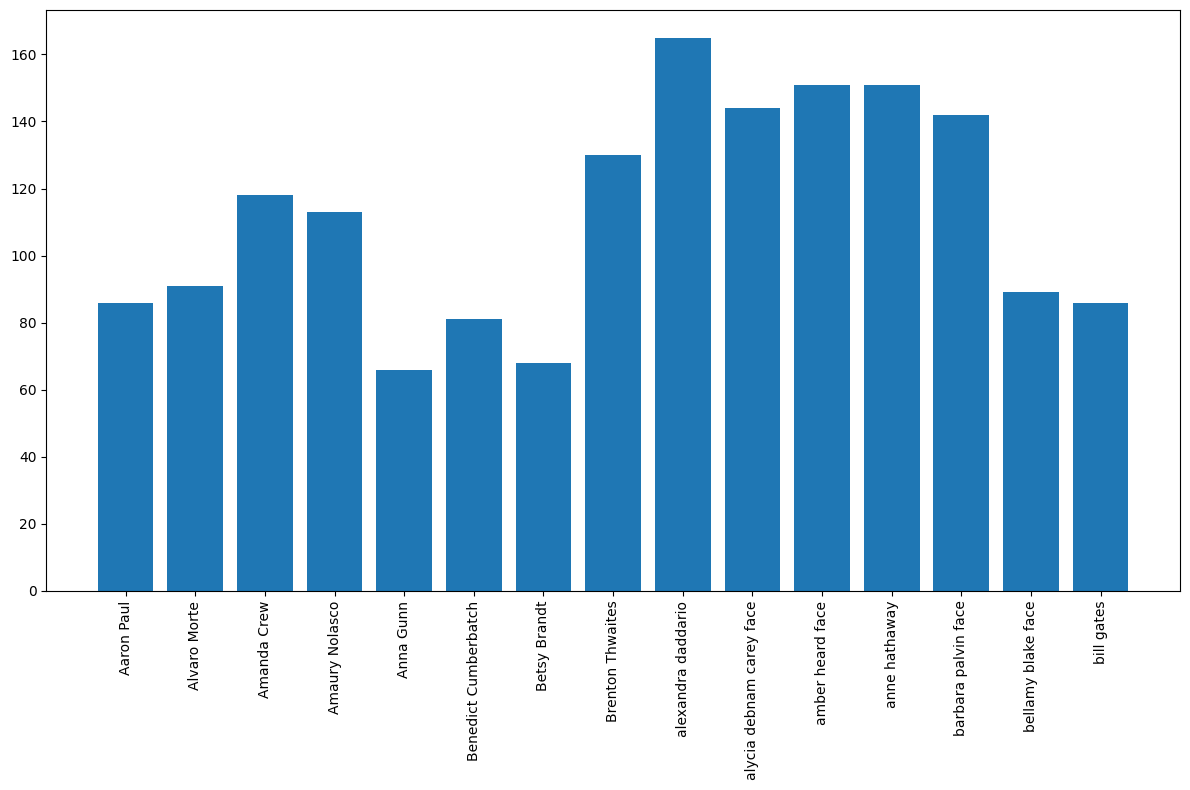

In [35]:
# Aantal voorbeelden (foto's) per klasse:
fig, ax = plt.subplots(figsize=(12,8))
unique_elements, counts_elements = np.unique(labels, return_counts=True) 
print(np.asarray((unique_elements, counts_elements)))
ax.bar(unique_elements, counts_elements)
ax.tick_params(axis='x', rotation=90)  # Of rotation=45 als dat mooier is
plt.tight_layout()
plt.show()

In [12]:
!pip install -q scikit-learn

You should consider upgrading via the '/usr/bin/python3 -m pip install --upgrade pip' command.


In [13]:
from sklearn.preprocessing import MinMaxScaler
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import confusion_matrix,accuracy_score
from sklearn.model_selection import train_test_split
from sklearn.utils import shuffle
from sklearn.metrics import classification_report
from sklearn.metrics import confusion_matrix, accuracy_score
from sklearn.preprocessing import OneHotEncoder
from sklearn import preprocessing
from sklearn.preprocessing import LabelBinarizer
import sklearn.metrics as metrics
from sklearn.utils import class_weight
from tensorflow.keras.utils import to_categorical

In [57]:
# Creëer een training set en test set. Zorg ervoor dat 30 procent van de afbeeldingen in de test set zitten.
from sklearn.preprocessing import LabelEncoder

# labels_array = np.array(labels)
# faces_array = np.array(faces)

# alle afbeeldingen en labels zijn momenteel gesorteerd -> shuffle toepassen:
faces_shuffled, labels_shuffled = shuffle(faces, labels, random_state=0)

# Train en test set maken:
X_train, X_test, y_train, y_test = train_test_split(faces_shuffled, labels_shuffled, test_size=0.30, random_state=0)

# Voor latere analyse: 
y_test_orig = y_test

# One hot encoding voor de labels:
label_encoder = LabelEncoder()
y_train_vec = label_encoder.fit_transform(y_train)
y_train = to_categorical(y_train_vec)

y_test_vec = label_encoder.fit_transform(y_test)
y_test = to_categorical(y_test_vec)
# De labels zijn momenteel tekst; dit moet one hot encoded worden:
# to_categorical kan enkel integers coderen, dus moeten de namen eerst naar integers:

X_train = np.array(X_train)
y_train = np.array(y_train)
X_test = np.array(X_test)
y_test = np.array(y_test)

In [58]:
print (X_train.shape[0])
print (y_train.shape[0])

1176
1176


In [16]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.callbacks import ModelCheckpoint
from tensorflow.keras.layers import Activation
from tensorflow.keras.optimizers import SGD
from tensorflow.keras.layers import Dense, Dropout, Flatten
from tensorflow.keras.layers import Conv2D, MaxPooling2D
from tensorflow.keras.layers import Dense, Dropout, Activation, BatchNormalization

In [17]:
# Convolutional Neural Network

# Model checkpoint
mc = ModelCheckpoint('Faces_15_best.h5', monitor='val_accuracy', mode='max', verbose=1, save_best_only=True)
# Early stopping
es = EarlyStopping(monitor='val_loss', mode='min', verbose=1, patience = 20)

image_shape = (image_size,image_size,3)
batch_size = 32
epochs = 100

model = Sequential()

model.add(Conv2D(filters=32,kernel_size=(3,3),input_shape=image_shape,activation='relu',))
model.add(MaxPooling2D(pool_size=(2,2)))
model.add(Dropout(0.5))
model.add(BatchNormalization())

model.add(Conv2D(filters=64,kernel_size=(3,3),activation='relu',))
model.add(MaxPooling2D(pool_size=(2,2)))
model.add(Dropout(0.5))
model.add(BatchNormalization())

model.add(Conv2D(filters=128,kernel_size=(3,3),activation='relu',))
model.add(MaxPooling2D(pool_size=(2,2)))
model.add(Dropout(0.5))
model.add(BatchNormalization())

model.add(Flatten())

model.add(Dense(128))
model.add(Activation('relu'))
model.add(Dropout(0.5))
model.add(BatchNormalization())

model.add(Dense(64))
model.add(Activation('relu'))
model.add(Dropout(0.5))
model.add(BatchNormalization())

model.add(Dense(15))
model.add(Activation('softmax'))

model.compile(loss='categorical_crossentropy',
             optimizer='adam',
             metrics=['accuracy']
             )

In [18]:
history = model.fit(X_train, y_train,  validation_data=(X_test, y_test), batch_size=batch_size, epochs=epochs,
                              callbacks=[es,mc], verbose=1)

Epoch 1/100
37/37 [==============================] - ETA: 0s - loss: 3.2063 - accuracy: 0.0918
Epoch 1: val_accuracy improved from -inf to 0.05941, saving model to Faces_15_best.h5
37/37 [==============================] - 3s 19ms/step - loss: 3.2063 - accuracy: 0.0918 - val_loss: 3.0970 - val_accuracy: 0.0594
Epoch 2/100
32/37 [========================>.....] - ETA: 0s - loss: 2.9614 - accuracy: 0.1113
Epoch 2: val_accuracy did not improve from 0.05941
37/37 [==============================] - 0s 8ms/step - loss: 2.9564 - accuracy: 0.1088 - val_loss: 3.8882 - val_accuracy: 0.0495
Epoch 3/100
33/37 [=========================>....] - ETA: 0s - loss: 2.8189 - accuracy: 0.1383
Epoch 3: val_accuracy improved from 0.05941 to 0.06337, saving model to Faces_15_best.h5
37/37 [==============================] - 0s 10ms/step - loss: 2.8384 - accuracy: 0.1327 - val_loss: 4.1936 - val_accuracy: 0.0634
Epoch 4/100
33/37 [=========================>....] - ETA: 0s - loss: 2.7208 - accuracy: 0.1591
Epoch

Epoch 29/100
33/37 [=========================>....] - ETA: 0s - loss: 1.5935 - accuracy: 0.4877
Epoch 29: val_accuracy did not improve from 0.50693
37/37 [==============================] - 0s 9ms/step - loss: 1.5890 - accuracy: 0.4898 - val_loss: 1.6490 - val_accuracy: 0.4970
Epoch 30/100
33/37 [=========================>....] - ETA: 0s - loss: 1.5575 - accuracy: 0.5028
Epoch 30: val_accuracy improved from 0.50693 to 0.53861, saving model to Faces_15_best.h5
37/37 [==============================] - 0s 10ms/step - loss: 1.5507 - accuracy: 0.5026 - val_loss: 1.6183 - val_accuracy: 0.5386
Epoch 31/100
32/37 [========================>.....] - ETA: 0s - loss: 1.5468 - accuracy: 0.4922
Epoch 31: val_accuracy improved from 0.53861 to 0.55248, saving model to Faces_15_best.h5
37/37 [==============================] - 0s 10ms/step - loss: 1.5271 - accuracy: 0.5026 - val_loss: 1.4933 - val_accuracy: 0.5525
Epoch 32/100
33/37 [=========================>....] - ETA: 0s - loss: 1.4834 - accuracy: 0.

33/37 [=========================>....] - ETA: 0s - loss: 0.9585 - accuracy: 0.6913
Epoch 57: val_accuracy improved from 0.73663 to 0.74653, saving model to Faces_15_best.h5
37/37 [==============================] - 0s 10ms/step - loss: 0.9716 - accuracy: 0.6896 - val_loss: 0.9311 - val_accuracy: 0.7465
Epoch 58/100
33/37 [=========================>....] - ETA: 0s - loss: 0.9469 - accuracy: 0.7093
Epoch 58: val_accuracy did not improve from 0.74653
37/37 [==============================] - 0s 8ms/step - loss: 0.9456 - accuracy: 0.7134 - val_loss: 0.9719 - val_accuracy: 0.7149
Epoch 59/100
33/37 [=========================>....] - ETA: 0s - loss: 0.8675 - accuracy: 0.7263
Epoch 59: val_accuracy did not improve from 0.74653
37/37 [==============================] - 0s 8ms/step - loss: 0.8853 - accuracy: 0.7236 - val_loss: 1.1867 - val_accuracy: 0.6535
Epoch 60/100
33/37 [=========================>....] - ETA: 0s - loss: 0.8943 - accuracy: 0.7121
Epoch 60: val_accuracy did not improve from 0.7

37/37 [==============================] - ETA: 0s - loss: 0.7567 - accuracy: 0.7679
Epoch 86: val_accuracy did not improve from 0.77822
37/37 [==============================] - 0s 13ms/step - loss: 0.7567 - accuracy: 0.7679 - val_loss: 0.7721 - val_accuracy: 0.7743
Epoch 87/100
34/37 [==========================>...] - ETA: 0s - loss: 0.6894 - accuracy: 0.7923
Epoch 87: val_accuracy did not improve from 0.77822
37/37 [==============================] - 0s 10ms/step - loss: 0.6887 - accuracy: 0.7874 - val_loss: 0.7215 - val_accuracy: 0.7782
Epoch 88/100
32/37 [========================>.....] - ETA: 0s - loss: 0.6694 - accuracy: 0.7881
Epoch 88: val_accuracy improved from 0.77822 to 0.78218, saving model to Faces_15_best.h5
37/37 [==============================] - 0s 11ms/step - loss: 0.6806 - accuracy: 0.7832 - val_loss: 0.7518 - val_accuracy: 0.7822
Epoch 89/100
33/37 [=========================>....] - ETA: 0s - loss: 0.6876 - accuracy: 0.7822
Epoch 89: val_accuracy improved from 0.78218 

In [19]:
y_pred = model.predict(X_test)

16/16 [==============================] - 0s 2ms/step


In [20]:
y_pred_classes = np.argmax(y_pred, axis=1)

In [21]:
# Testen van het CNN
# Performantie op de test data

# Accuracy
print('\n')
print('accuracy score:', accuracy_score(y_test_vec, y_pred_classes) * 100) 
print('\n')

# Recall, precision, f1-score:
print ("Classification report:\n")
print(classification_report(y_test_vec, y_pred_classes))

# Confusion matrix
cf = confusion_matrix(y_test_vec, y_pred_classes)
print("Confusion matrix:\n\n",cf)



accuracy score: 77.22772277227723


Classification report:

              precision    recall  f1-score   support

           0       0.82      0.67      0.74        21
           1       0.76      0.93      0.84        30
           2       0.63      0.93      0.75        29
           3       0.94      0.85      0.89        40
           4       1.00      0.84      0.91        19
           5       0.67      0.70      0.68        23
           6       0.94      0.74      0.83        23
           7       0.67      0.92      0.77        50
           8       0.95      0.64      0.76        58
           9       0.67      0.75      0.71        40
          10       0.75      0.83      0.79        47
          11       0.84      0.59      0.70        27
          12       0.68      0.57      0.62        44
          13       0.75      0.72      0.73        25
          14       0.93      0.93      0.93        29

    accuracy                           0.77       505
   macro avg      

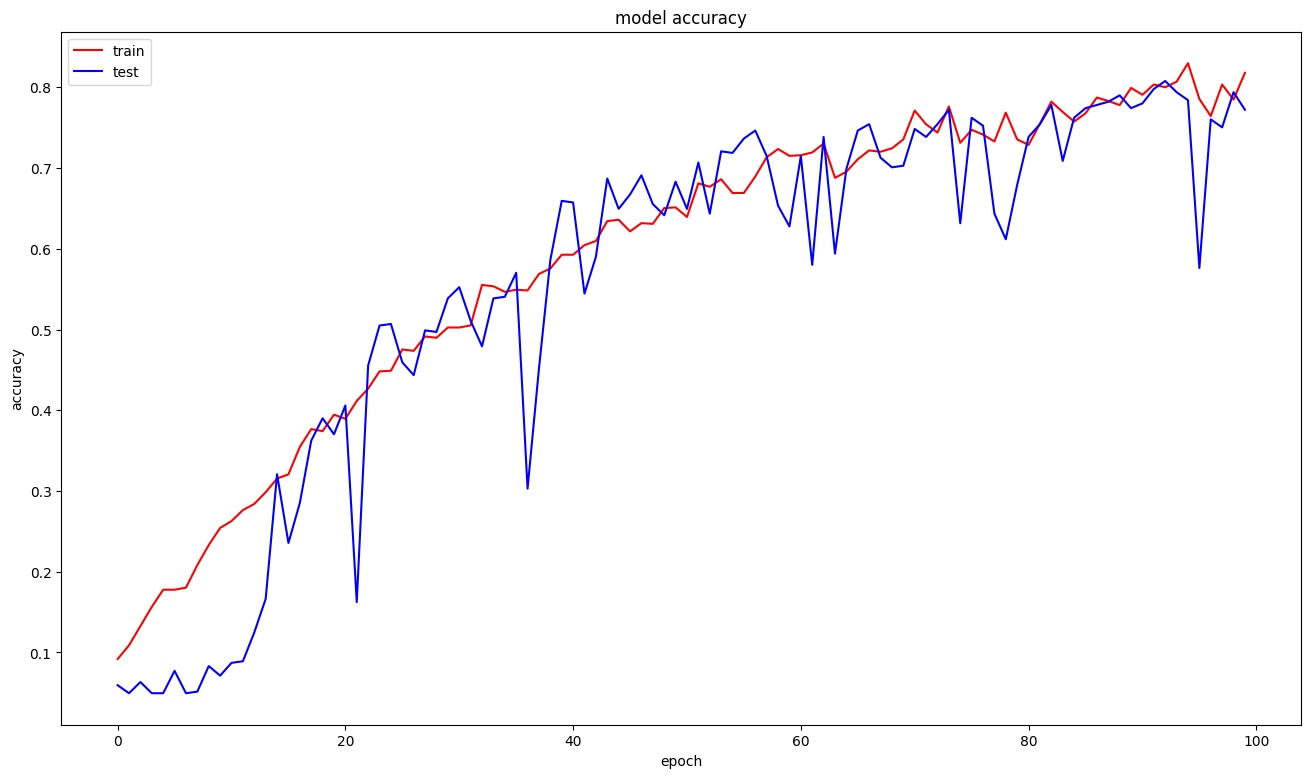

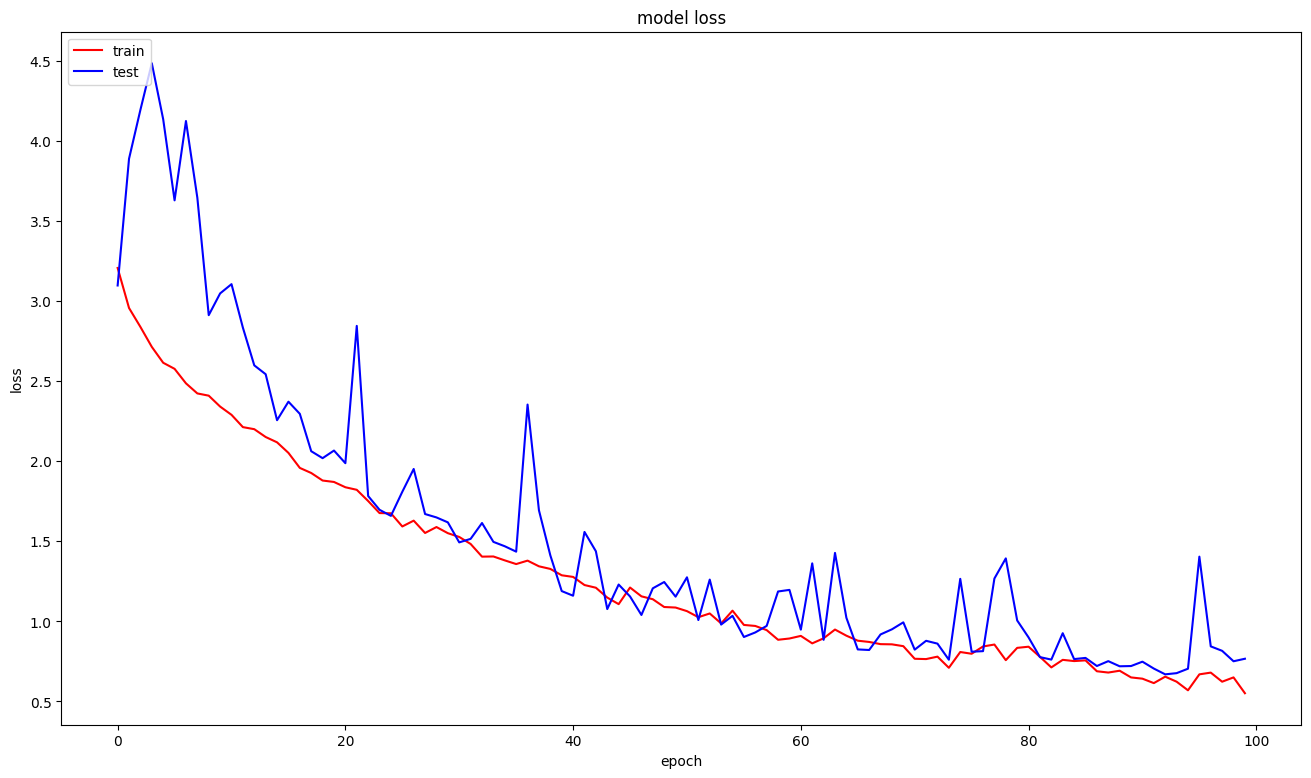

In [22]:
# Accuray 
fig = plt.figure(figsize=(16,9))
plt.plot(history.history['accuracy'],'r')
plt.plot(history.history['val_accuracy'],'b')
plt.title('model accuracy')
plt.ylabel('accuracy')
plt.xlabel('epoch')
plt.legend(['train', 'test'], loc='upper left')
plt.show()
# Loss 
fig = plt.figure(figsize=(16,9))
plt.plot(history.history['loss'],'r')
plt.plot(history.history['val_loss'],'b')

plt.title('model loss')
plt.ylabel('loss')
plt.xlabel('epoch')
plt.legend(['train', 'test'], loc='upper left')
plt.show()

### Samenvatting

Convolutionele neurale netwerken zijn krachtige modellen voor computer vision, die werken door lokale patronen te leren via convolutionele lagen en feature maps. Max pooling is een belangrijke operatie voor het downsamplen van feature maps en het bevorderen van ruimtelijke hiërarchieën in de geleerde kenmerken. Bij het werken met kleine datasets zijn technieken zoals data-augmentatie, feature extractie en fine-tuning essentieel om goede resultaten te behalen.